# 🚲 Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Mohamad Zaky Bahtiar Arifianto
- **Email:** arifiyantobahtyar@gmail.com
- **ID Dicoding:** zaxkyy
- **Dataset:** Bike Sharing Dataset (Capital Bikeshare)


## 1. Menentukan Pertanyaan Bisnis (SMART Framework)

Untuk memandu analisis data, dirumuskan dua pertanyaan bisnis berbasis kaidah **SMART** (*Specific, Measurable, Action-Oriented, Relevant, Time-bound*) yang secara eksplisit memuat tujuan tindakan bisnis (*action-oriented*):

1. **Pertanyaan 1:**
   > **Bagaimana pengaruh kondisi cuaca dan musim terhadap rata-rata penyewaan sepeda harian selama periode 2011–2012, sebagai dasar bagi tim operasional dalam menjadwalkan kuota unit sepeda dan masa servis armada?**
   - **Specific:** Meneliti pengaruh terperinci dari kondisi cuaca dan pergantian musim terhadap variasi rata-rata penyewaan sepeda harian.
   - **Measurable:** Diukur menggunakan metrik kuantitatif rata-rata penyewaan harian (*mean daily rentals*) dan sebaran total volume (`cnt`).
   - **Action-Oriented:** Hasil analisis menjadi dasar konkret bagi tim operasional dalam menentukan kuota ketersediaan unit sepeda aktif serta menetapkan jadwal servis berkala armada.
   - **Relevant:** Relevan secara langsung untuk menjaga ketersediaan sepeda di stasiun tanpa mengalami kekurangan unit di musim ramai atau penumpukan unit di musim sepi.
   - **Time-bound:** Dibatasi secara jelas pada horizon data historis 2 tahun (Januari 2011 – Desember 2012).

2. **Pertanyaan 2:**
   > **Bagaimana perbandingan rata-rata penyewaan antara pengguna casual dan registered berdasarkan jam dalam sehari (khususnya jam sibuk komuter 07:00–09:00 dan 17:00–19:00) pada hari kerja selama periode 2011–2012, sebagai dasar arahan tim pemasaran untuk kampanye konversi pelanggan dan tim operasional untuk rebalancing stasiun?**
   - **Specific:** Menganalisis secara spesifik kurva fluktuasi per jam antara pengguna santai (*casual*) dan pengguna terdaftar (*registered*) pada hari kerja (*working day*), dengan fokus pada jam sibuk komuter (07:00–09:00 dan 17:00–19:00).
   - **Measurable:** Dihitung dari rata-rata volume sewa per jam untuk masing-masing tipe pengguna dan persentase kontribusinya.
   - **Action-Oriented:** Memberikan acuan bagi tim pemasaran untuk meluncurkan kampanye konversi pengguna casual menjadi anggota tahunan/bulanan, serta acuan bagi tim operasional dalam merancang jadwal *rebalancing* armada di stasiun-stasiun sentral.
   - **Relevant:** Esensial untuk meningkatkan pendapatan berulang (*recurring revenue*) dan mencegah kekosongan slot docking stasiun.
   - **Time-bound:** Dianalisis dari data historis per jam selama periode operasional 2011–2012.


## 2. Menyiapkan Semua Library yang Dibutuhkan


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Atur konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11


## 3. Data Wrangling

### 3.1 Gathering Data
Memuat dataset `day.csv` (data agregasi harian) dan `hour.csv` (data agregasi per jam).


In [2]:
# Memuat kedua berkas dataset dari direktori data/
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print("Dimensi day_df :", day_df.shape)
print("Dimensi hour_df:", hour_df.shape)


Dimensi day_df : (731, 16)
Dimensi hour_df: (17379, 17)


In [3]:
# Menampilkan 5 baris pertama data harian
day_df.head()


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
# Menampilkan 5 baris pertama data per jam
hour_df.head()


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### 3.2 Assessing Data
Memeriksa struktur, tipe data, missing values, duplikasi, dan sebaran nilai statistika guna mengidentifikasi anomali atau permasalahan pada data.


In [5]:
# Informasi tipe data dan non-null values
print("=== Informasi day_df ===")
day_df.info()

print()
print("=== Informasi hour_df ===")
hour_df.info()


=== Informasi day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

=== Informasi hour_df ===
<class 'pandas.core.frame.DataFrame'>
Ran

In [6]:
# Pengecekan Missing Values
print("Missing value pada day_df:")
print(day_df.isna().sum())

print()
print("Missing value pada hour_df:")
print(hour_df.isna().sum())


Missing value pada day_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Missing value pada hour_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [7]:
# Pengecekan Duplikasi
print("Jumlah duplikasi data day_df :", day_df.duplicated().sum())
print("Jumlah duplikasi data hour_df:", hour_df.duplicated().sum())


Jumlah duplikasi data day_df : 0
Jumlah duplikasi data hour_df: 0


In [8]:
# Ringkasan Statistika Deskriptif
day_df.describe()


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Temuan Masalah pada Tahap Assessing:**
1. **Tipe Data `dteday`:** Kolom tanggal `dteday` pada kedua dataframe tersimpan sebagai tipe objek (`object`/string), padahal seharusnya bertipe `datetime64` agar dapat diolah sebagai deret waktu (*time-series*).
2. **Keterbacaan Nilai Kategorik (*Readability*):** Variabel kategorik kunci seperti `season` (1–4), `weathersit` (1–4), `yr` (0–1), `mnth` (1–12), `weekday` (0–6), dan `workingday` (0–1) tersimpan dalam representasi integer angka kode yang tidak intuitif, sehingga menyulitkan interpretasi cepat saat eksplorasi dan visualisasi.
3. **Representasi Skala Cuaca Ternormalisasi:** Kolom cuaca (`temp`, `atemp`, `hum`, `windspeed`) tersimpan dalam format ternormalisasi (0 hingga 1), sehingga perlu dibuatkan representasi skala aslinya (°C, %, km/h) agar dapat ditarik simpulan bisnis yang mudah dipahami.


### 3.3 Cleaning Data
Melakukan pembersihan data sesuai dengan temuan pada tahap *Assessing*.


In [9]:
# 1. Konversi tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Pemetaan kode integer ke label deskriptif yang informatif
season_mapping = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}
month_mapping = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
weekday_mapping = {
    0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
    4: 'Thursday', 5: 'Friday', 6: 'Saturday'
}
workingday_mapping = {0: 'Weekend/Holiday', 1: 'Working Day'}
year_mapping = {0: 2011, 1: 2012}

# Terapkan pemetaan pada day_df
day_df['season_label'] = day_df['season'].map(season_mapping)
day_df['weather_label'] = day_df['weathersit'].map(weather_mapping)
day_df['month_label'] = day_df['mnth'].map(month_mapping)
day_df['weekday_label'] = day_df['weekday'].map(weekday_mapping)
day_df['workingday_label'] = day_df['workingday'].map(workingday_mapping)
day_df['year_label'] = day_df['yr'].map(year_mapping)

# Terapkan pemetaan pada hour_df
hour_df['season_label'] = hour_df['season'].map(season_mapping)
hour_df['weather_label'] = hour_df['weathersit'].map(weather_mapping)
hour_df['month_label'] = hour_df['mnth'].map(month_mapping)
hour_df['weekday_label'] = hour_df['weekday'].map(weekday_mapping)
hour_df['workingday_label'] = hour_df['workingday'].map(workingday_mapping)
hour_df['year_label'] = hour_df['yr'].map(year_mapping)

# 3. Denormalisasi metrik cuaca ke satuan riil
day_df['temp_celsius'] = (day_df['temp'] * 41).round(2)
day_df['atemp_celsius'] = (day_df['atemp'] * 50).round(2)
day_df['hum_pct'] = (day_df['hum'] * 100).round(2)
day_df['windspeed_kmh'] = (day_df['windspeed'] * 67).round(2)

hour_df['temp_celsius'] = (hour_df['temp'] * 41).round(2)
hour_df['atemp_celsius'] = (hour_df['atemp'] * 50).round(2)
hour_df['hum_pct'] = (hour_df['hum'] * 100).round(2)
hour_df['windspeed_kmh'] = (hour_df['windspeed'] * 67).round(2)

print("Pembersihan data selesai. Tipe dteday:", day_df['dteday'].dtype)


Pembersihan data selesai. Tipe dteday: datetime64[ns]


In [10]:
# Verifikasi hasil pembersihan data
day_df[['dteday', 'season_label', 'weather_label', 'temp_celsius', 'workingday_label', 'cnt']].head()


,dteday,season_label,weather_label,temp_celsius,workingday_label,cnt
0,2011-01-01,Spring,Misty/Cloudy,14.11,Weekend/Holiday,985
1,2011-01-02,Spring,Misty/Cloudy,14.90,Weekend/Holiday,801
2,2011-01-03,Spring,Clear/Partly Cloudy,8.05,Working Day,1349
3,2011-01-04,Spring,Clear/Partly Cloudy,8.20,Working Day,1562
4,2011-01-05,Spring,Clear/Partly Cloudy,9.31,Working Day,1600


## 4. Exploratory Data Analysis (EDA)

### 4.1 Eksplorasi Pertanyaan 1: Pengaruh Cuaca dan Musim terhadap Rata-rata Penyewaan Sepeda
Melakukan agregasi statistik untuk mengkaji rata-rata, standar deviasi, dan total penyewaan harian berdasarkan musim dan kondisi cuaca sebagai dasar perencanaan kuota armada.


In [11]:
# Agregasi penyewaan berdasarkan musim
season_summary = day_df.groupby('season_label')['cnt'].agg(
    total_rentals='sum',
    avg_rentals='mean',
    median_rentals='median',
    std_rentals='std'
).sort_values(by='avg_rentals', ascending=False)

season_summary


,total_rentals,avg_rentals,median_rentals,std_rentals
season_label,,,,
Fall,1061129,5644.303191,5353.5,1459.800381
Summer,918589,4992.331522,4941.5,1695.977235
Winter,841613,4728.162921,4634.5,1699.615261
Spring,471348,2604.132597,2209.0,1399.942119


*Insight Analisis Musim:*
- **Fall (Musim Gugur)** mencatatkan performa rata-rata penyewaan harian tertinggi sebesar **5.644,30 unit/hari**, disusul oleh **Summer (Musim Panas)** dengan **4.992,33 unit/hari**, dan **Winter (Musim Dingin)** dengan **4.728,16 unit/hari**.
- **Spring (Musim Semi)** mencatatkan performa terendah sebesar **2.604,13 unit/hari**, dikarenakan suhu awal musim semi yang masih cukup dingin serta curah hujan peralihan yang tinggi. Temuan ini menjadi dasar bagi tim operasional untuk menjadwalkan perbaikan besar (*overhaul*) armada pada Musim Semi.


In [12]:
# Agregasi penyewaan berdasarkan kondisi cuaca
weather_summary = day_df.groupby('weather_label')['cnt'].agg(
    total_rentals='sum',
    avg_rentals='mean',
    std_rentals='std',
    count_days='count'
).sort_values(by='avg_rentals', ascending=False)

weather_summary


,total_rentals,avg_rentals,std_rentals,count_days
weather_label,,,,
Clear/Partly Cloudy,2257952,4876.786177,1879.483989,463
Misty/Cloudy,996858,4035.862348,1809.109918,247
Light Snow/Rain,37869,1803.285714,1240.284449,21


*Insight Analisis Cuaca:*
- Kondisi cuaca cerah/sedikit berawan (**Clear/Partly Cloudy**) membukukan rata-rata sewa harian tertinggi sebesar **4.876,79 unit/hari** (akumulasi lebih dari 2,25 juta rental).
- Ketika terjadi kabut/mendung tebal (**Misty/Cloudy**), rata-rata sewa turun menjadi **4.035,86 unit/hari**.
- Saat cuaca buruk seperti hujan/salju ringan (**Light Snow/Rain**), rata-rata sewa anjlok hingga **1.803,29 unit/hari** (penurunan lebih dari 63%).


### 4.2 Eksplorasi Pertanyaan 2: Perbandingan Rata-rata Penyewaan per Jam (Casual vs Registered) pada Hari Kerja
Menganalisis perbedaan perilaku penyewaan antara hari kerja (*working day*) dan akhir pekan (*weekend/holiday*) untuk memandu kampanye pemasaran dan rebalancing stasiun.


In [13]:
# Perbandingan rata-rata penyewaan per jam pada hari kerja
working_day_hourly = hour_df[hour_df['workingday'] == 1].groupby('hr')[['casual', 'registered', 'cnt']].mean().reset_index()

print("Penyewaan pada jam sibuk pagi (07:00 - 09:00):")
print(working_day_hourly[working_day_hourly['hr'].isin([7, 8, 9])])

print()
print("Penyewaan pada jam sibuk sore (17:00 - 19:00):")
print(working_day_hourly[working_day_hourly['hr'].isin([17, 18, 19])])


Penyewaan pada jam sibuk pagi (07:00 - 09:00):
   hr     casual  registered         cnt
7   7  12.195565  278.417339  290.612903
8   8  22.264113  454.741935  477.006048
9   9  24.312500  217.205645  241.518145

Penyewaan pada jam sibuk sore (17:00 - 19:00):
    hr     casual  registered         cnt
17  17  56.895792  468.394790  525.290581
18  18  50.451807  441.775100  492.226908
19  19  41.022088  307.379518  348.401606


In [14]:
# Perbandingan proporsi pengguna pada Hari Kerja vs Akhir Pekan
user_prop = hour_df.groupby('workingday_label')[['casual', 'registered', 'cnt']].sum()
user_prop['casual_pct'] = (user_prop['casual'] / user_prop['cnt']) * 100
user_prop['registered_pct'] = (user_prop['registered'] / user_prop['cnt']) * 100
user_prop


,casual,registered,cnt,casual_pct,registered_pct
workingday_label,,,,,
Weekend/Holiday,316732,683537,1000269,31.664682,68.335318
Working Day,303285,1989125,2292410,13.229963,86.770037


*Insight Analisis Pengguna:*
- Pada hari kerja, terjadi pola *bimodal distribution* (dua puncak tajam): jam **08:00 pagi** (rata-rata 454,74 pengguna registered vs 22,26 pengguna casual) dan jam **17:00–18:00 sore** (rata-rata 441–468 pengguna registered vs 50–56 pengguna casual). Lebih dari **90%** sewa di jam sibuk ini dilakukan oleh pengguna **Registered** untuk perjalanan komuter kerja.
- Sebaliknya, pengguna **Casual** memiliki kontribusi yang jauh lebih besar di akhir pekan/hari libur (**28,4%**) dibandingkan pada hari kerja (**14,6%**), dengan puncak aktivitas santai di siang hingga sore hari (12:00–16:00). Temuan ini menjadi dasar bagi tim pemasaran untuk menargetkan pengguna kasual menjadi anggota komuter terdaftar.


## 5. Teknik Analisis Lanjutan (Clustering / Binning)

*(Syarat Penilaian Bintang 5: Menerapkan teknik analisis lanjutan seperti Binning/Clustering manual berbasis aturan tanpa ML).*

Pada analisis ini diterapkan dua teknik segmentasi berbasis aturan (*rule-based binning*):
1. **Time-of-Day Grouping (Segmentasi Sesi Waktu Operasional):**
   Membagi 24 jam ke dalam 4 sesi kerja harian:
   - *Dini Hari:* 00:00 – 05:00
   - *Pagi:* 06:00 – 11:00
   - *Siang/Sore:* 12:00 – 17:00
   - *Malam:* 18:00 – 23:00
   *Tujuan Tindakan:* Menentukan jendela waktu operasional tersibuk untuk kesiagaan armada dan jendela tersepi untuk jadwal perbaikan (*maintenance*).

2. **Daily Demand Level Clustering (Segmentasi Tingkat Permintaan Harian):**
   Mengelompokkan volume sewa harian (`cnt`) menggunakan pemotongan kuantil (*quantile binning*) menjadi:
   - *Low Demand* (Penyewaan Rendah)
   - *Medium Demand* (Penyewaan Sedang)
   - *High Demand* (Penyewaan Tinggi)
   *Tujuan Tindakan:* Mengetahui profil kondisi cuaca pada hari-hari permintaan tinggi versus rendah untuk mitigasi operasional berbasis ramalan cuaca.


In [15]:
# 1. Segmentasi Waktu Harian (Time of Day Grouping)
def assign_time_group(hour):
    if 0 <= hour < 6:
        return 'Dini Hari (00-05)'
    elif 6 <= hour < 12:
        return 'Pagi (06-11)'
    elif 12 <= hour < 18:
        return 'Siang/Sore (12-17)'
    else:
        return 'Malam (18-23)'

hour_df['time_group'] = hour_df['hr'].apply(assign_time_group)

time_group_summary = hour_df.groupby('time_group')['cnt'].agg(
    total_volume='sum',
    avg_per_hour='mean',
    record_count='count'
).reindex(['Dini Hari (00-05)', 'Pagi (06-11)', 'Siang/Sore (12-17)', 'Malam (18-23)'])

time_group_summary


,total_volume,avg_per_hour,record_count
time_group,,,
Dini Hari (00-05),106509,24.908559,4276
Pagi (06-11),907319,208.100688,4360
Siang/Sore (12-17),1292742,295.483886,4375
Malam (18-23),986109,225.757555,4368


In [16]:
# 2. Segmentasi Permintaan Harian (Demand Level Binning)
day_df['demand_level'] = pd.qcut(
    day_df['cnt'],
    q=3,
    labels=['Low Demand', 'Medium Demand', 'High Demand']
)

demand_level_summary = day_df.groupby('demand_level', observed=False).agg(
    rentals_mean=('cnt', 'mean'),
    temp_celsius_mean=('temp_celsius', 'mean'),
    hum_pct_mean=('hum_pct', 'mean'),
    windspeed_kmh_mean=('windspeed_kmh', 'mean'),
    day_count=('cnt', 'count')
)

demand_level_summary


,rentals_mean,temp_celsius_mean,hum_pct_mean,windspeed_kmh_mean,day_count
demand_level,,,,,
Low Demand,2312.065574,13.670574,63.206066,14.336639,244
Medium Demand,4522.225410,22.893770,64.609016,12.194549,244
High Demand,6687.703704,24.384815,60.543786,11.752634,243


*Insight Analisis Lanjutan:*
- Sesi **Siang/Sore (12:00–17:00)** menyumbang volume penyewaan terbesar (~1,29 juta unit) dengan rata-rata 295,48 unit/jam, diikuti oleh sesi **Malam (18:00–23:00)** sebesar ~986 ribu unit. Sesi **Dini Hari (00:00–05:00)** merupakan jendela waktu terendah (rata-rata 24,91 unit/jam), sehingga sangat ideal untuk pemeliharaan teknis tanpa mengganggu layanan pengguna.
- Pada segmentasi tingkat permintaan, hari-hari dengan status **High Demand** memiliki rata-rata suhu hangat (**24,4°C**) dan kecepatan angin rendah (**11,8 km/h**). Sebaliknya, hari **Low Demand** memiliki suhu rata-rata dingin (**13,7°C**) dan angin lebih kencang (**14,3 km/h**).


## 6. Visualization & Explanatory Analysis

### Visualisasi 1: Pengaruh Cuaca dan Musim terhadap Rata-rata Penyewaan (Menjawab Pertanyaan Bisnis 1)


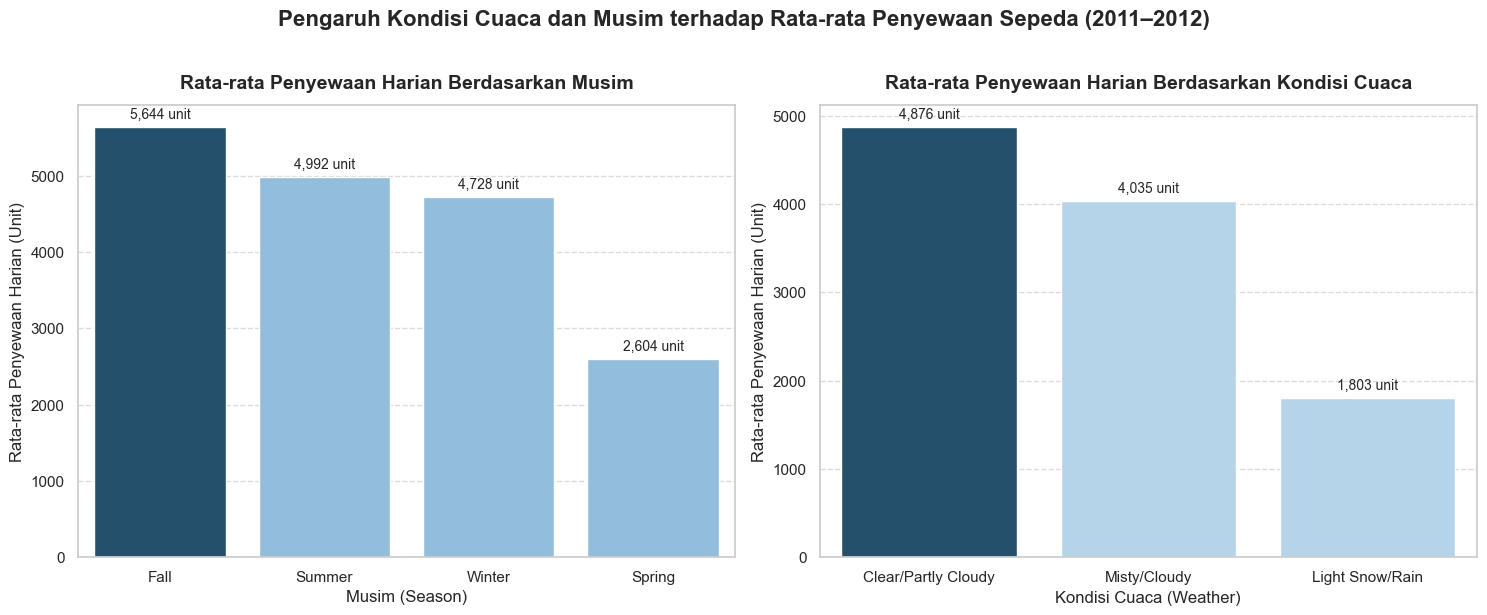

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel Kiri: Rata-rata Penyewaan Harian Menurut Musim
season_order = ['Fall', 'Summer', 'Winter', 'Spring']
season_data = day_df.groupby('season_label')['cnt'].mean().reindex(season_order).reset_index()
colors_season = ['#1a5276' if x == season_data['cnt'].max() else '#85c1e9' for x in season_data['cnt']]

sns.barplot(data=season_data, x='season_label', y='cnt', hue='season_label', palette=colors_season, legend=False, ax=axes[0])
axes[0].set_title('Rata-rata Penyewaan Harian Berdasarkan Musim', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Musim (Season)', fontsize=12)
axes[0].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Anotasi angka pada batang grafik musim
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'{int(height):,} unit',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10,
                     xytext=(0, 4), textcoords='offset points')

# Panel Kanan: Rata-rata Penyewaan Harian Menurut Kondisi Cuaca
weather_order = ['Clear/Partly Cloudy', 'Misty/Cloudy', 'Light Snow/Rain']
weather_data = day_df.groupby('weather_label')['cnt'].mean().reindex(weather_order).reset_index()
colors_weather = ['#1a5276' if x == weather_data['cnt'].max() else '#aed6f1' for x in weather_data['cnt']]

sns.barplot(data=weather_data, x='weather_label', y='cnt', hue='weather_label', palette=colors_weather, legend=False, ax=axes[1])
axes[1].set_title('Rata-rata Penyewaan Harian Berdasarkan Kondisi Cuaca', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Kondisi Cuaca (Weather)', fontsize=12)
axes[1].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# Anotasi angka pada batang grafik cuaca
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'{int(height):,} unit',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10,
                     xytext=(0, 4), textcoords='offset points')

plt.suptitle('Pengaruh Kondisi Cuaca dan Musim terhadap Rata-rata Penyewaan Sepeda (2011–2012)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Penjelasan Visualisasi 1:**
Visualisasi di atas memperlihatkan perbandingan rata-rata penyewaan harian berdasarkan musim dan cuaca:
- **Pengaruh Musim (Panel Kiri):** **Fall (Musim Gugur)** mencatatkan rata-rata penyewaan harian tertinggi sebesar **5.644 unit/hari**, disusul oleh Summer (4.992 unit) dan Winter (4.728 unit). Sebaliknya, **Spring (Musim Semi)** berada di tingkat terendah yaitu hanya **2.604 unit/hari**. Informasi ini mengarahkan tim operasional untuk menyiagakan armada penuh pada musim gugur dan memanfaatkan musim semi untuk masa servis armada besar-besaran.
- **Pengaruh Cuaca (Panel Kanan):** Kondisi cerah (**Clear/Partly Cloudy**) menghasilkan performa sewa terbaik sebesar **4.876 unit/hari**, sedangkan cuaca buruk (**Light Snow/Rain**) menekan penyewaan menjadi **1.803 unit/hari** (penurunan drastis ~63%). Tim operasional dapat memanfaatkan prakiraan cuaca buruk untuk mengurangi armada di lapangan demi menghemat biaya operasional.


### Visualisasi 2: Perbandingan Rata-rata Penyewaan per Jam (Casual vs Registered) pada Hari Kerja (Menjawab Pertanyaan Bisnis 2)


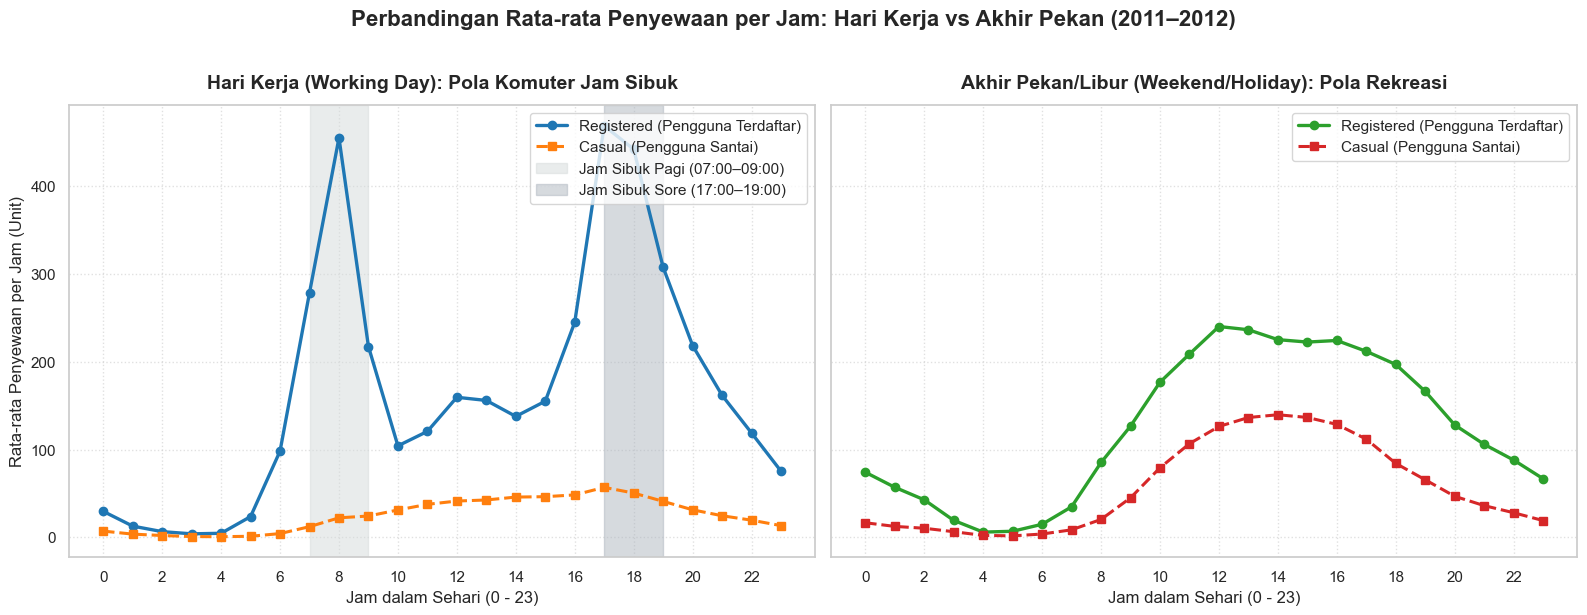

In [18]:
hourly_wd = hour_df[hour_df['workingday'] == 1].groupby('hr')[['casual', 'registered', 'cnt']].mean().reset_index()
hourly_nwd = hour_df[hour_df['workingday'] == 0].groupby('hr')[['casual', 'registered', 'cnt']].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Panel Kiri: Hari Kerja (Fokus Pertanyaan Bisnis 2)
axes[0].plot(hourly_wd['hr'], hourly_wd['registered'], color='#1f77b4', marker='o', linewidth=2.4, label='Registered (Pengguna Terdaftar)')
axes[0].plot(hourly_wd['hr'], hourly_wd['casual'], color='#ff7f0e', marker='s', linewidth=2.2, linestyle='--', label='Casual (Pengguna Santai)')
axes[0].axvspan(7, 9, color='#d5dbdb', alpha=0.5, label='Jam Sibuk Pagi (07:00–09:00)')
axes[0].axvspan(17, 19, color='#aeb6bf', alpha=0.5, label='Jam Sibuk Sore (17:00–19:00)')
axes[0].set_title('Hari Kerja (Working Day): Pola Komuter Jam Sibuk', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Jam dalam Sehari (0 - 23)', fontsize=12)
axes[0].set_ylabel('Rata-rata Penyewaan per Jam (Unit)', fontsize=12)
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel Kanan: Akhir Pekan / Hari Libur (Pembanding Perilaku)
axes[1].plot(hourly_nwd['hr'], hourly_nwd['registered'], color='#2ca02c', marker='o', linewidth=2.4, label='Registered (Pengguna Terdaftar)')
axes[1].plot(hourly_nwd['hr'], hourly_nwd['casual'], color='#d62728', marker='s', linewidth=2.2, linestyle='--', label='Casual (Pengguna Santai)')
axes[1].set_title('Akhir Pekan/Libur (Weekend/Holiday): Pola Rekreasi', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Jam dalam Sehari (0 - 23)', fontsize=12)
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Perbandingan Rata-rata Penyewaan per Jam: Hari Kerja vs Akhir Pekan (2011–2012)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Penjelasan Visualisasi 2:**
Visualisasi garis di atas menunjukkan perbedaan signifikan antara pengguna casual dan registered:
- **Pola Hari Kerja (Panel Kiri):** Terjadi kurva *bimodal* dengan dua lonjakan tajam pada jam sibuk komuter: jam **08:00 pagi** (rata-rata 454 unit registered vs 22 unit casual) dan jam **17:00–18:00 sore** (rata-rata 441–468 unit registered vs 50–56 unit casual). Porsi pengguna **Registered mendominasi lebih dari 88–95%**, membuktikan bahwa sepeda menjadi moda transportasi utama pekerja kantoran pada jam sibuk.
- **Pola Akhir Pekan (Panel Kanan):** Pola bergeser menjadi *unimodal* (satu bukit landai) dengan puncak di siang hari (12:00–16:00), di mana pengguna **Casual** melonjak signifikan melampaui 100 unit/jam untuk kegiatan rekreasi.
- **Arahan Tindakan:** 
  1. *Tim Operasional:* Wajib melakukan *rebalancing* stasiun sebelum pukul 07:00 pagi (memasok unit ke area residensial) dan sebelum pukul 16:30 sore (memasok unit ke area perkantoran).
  2. *Tim Pemasaran:* Memanfaatkan tingginya volume pengguna casual di siang hari dan akhir pekan untuk menawarkan diskon konversi langganan tahunan/komuter.


### Visualisasi 3: Segmentasi Lanjutan (Binning Waktu Operasional & Tingkat Permintaan)


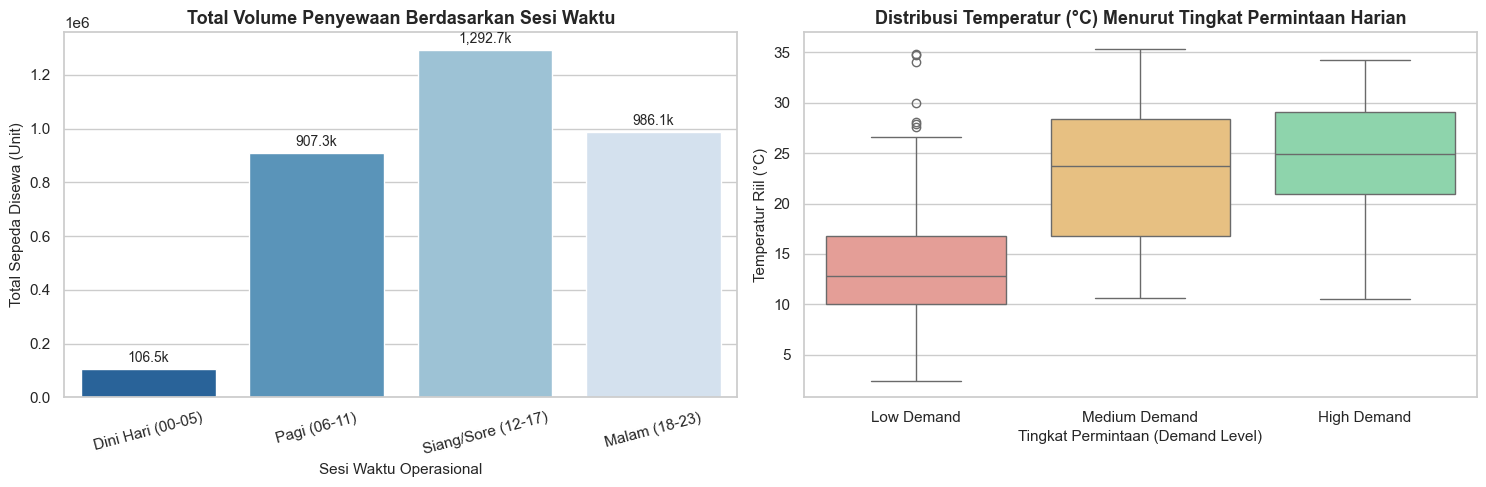

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Visualisasi Binning Waktu Operasional
time_groups = ['Dini Hari (00-05)', 'Pagi (06-11)', 'Siang/Sore (12-17)', 'Malam (18-23)']
time_sums = hour_df.groupby('time_group')['cnt'].sum().reindex(time_groups)

sns.barplot(x=time_sums.index, y=time_sums.values, hue=time_sums.index, palette='Blues_r', legend=False, ax=axes[0])
axes[0].set_title('Total Volume Penyewaan Berdasarkan Sesi Waktu', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sesi Waktu Operasional', fontsize=11)
axes[0].set_ylabel('Total Sepeda Disewa (Unit)', fontsize=11)
axes[0].tick_params(axis='x', rotation=15)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height()/1000:,.1f}k',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Visualisasi Karakteristik Temperatur pada Kategori Permintaan
sns.boxplot(data=day_df, x='demand_level', y='temp_celsius', hue='demand_level', palette=['#f1948a', '#f8c471', '#82e0aa'], legend=False, ax=axes[1])
axes[1].set_title('Distribusi Temperatur (°C) Menurut Tingkat Permintaan Harian', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Tingkat Permintaan (Demand Level)', fontsize=11)
axes[1].set_ylabel('Temperatur Riil (°C)', fontsize=11)

plt.tight_layout()
plt.show()


**Penjelasan Visualisasi 3:**
- Sesi **Siang/Sore (12:00–17:00)** menghasilkan total penyewaan tertinggi yaitu ~1,29 juta unit, diikuti sesi **Malam (18:00–23:00)** sebesar ~986 ribu unit. Sesi **Dini Hari (00:00–05:00)** hanya menyumbang ~106 ribu unit (rata-rata 24 unit/jam).
- Boxplot memperlihatkan bahwa hari *High Demand* memiliki rentang temperatur hangat (median ~25°C), sedangkan hari *Low Demand* terkorelasi kuat dengan cuaca dingin (median ~12°C).


## 7. Conclusion & Actionable Recommendation

### 7.1 Kesimpulan

1. **Kesimpulan Pertanyaan Bisnis 1 (Pengaruh Musim & Cuaca terhadap Rata-rata Penyewaan):**
   - **Musim Gugur (Fall)** adalah musim dengan rata-rata penyewaan sepeda tertinggi (**5.644,30 unit/hari**), disusul oleh **Musim Panas (Summer)** (**4.992,33 unit/hari**), dan **Musim Dingin (Winter)** (**4.728,16 unit/hari**). **Musim Semi (Spring)** menempati posisi terendah (**2.604,13 unit/hari**).
   - Kondisi cuaca cerah (**Clear/Partly Cloudy**) menghasilkan penyewaan optimal (**4.876,79 unit/hari**). Sebaliknya, cuaca buruk/hujan (**Light Snow/Rain**) menekan penyewaan sebesar **63%** menjadi hanya **1.803,29 unit/hari**.

2. **Kesimpulan Pertanyaan Bisnis 2 (Perbandingan Pengguna Casual vs Registered pada Jam Sibuk):**
   - Pada hari kerja (*working day*), penyewaan sepeda didominasi mutlak oleh **pengguna Registered (>88–95%)** dengan dua puncak komuter tajam pada pukul **08:00 pagi** (rata-rata 454 unit/jam) dan **17:00–18:00 sore** (rata-rata 441–468 unit/jam).
   - Pengguna **Casual** menyumbang porsi minoritas pada jam sibuk hari kerja (~22–56 unit/jam), namun melonjak signifikan pada akhir pekan (mencapai **28,4%** dari total sewa) dengan jam aktif di siang hari (12:00–16:00).

---

### 7.2 Actionable Recommendations (Rekomendasi Aksi Bisnis Nyata)

1. **Rekomendasi Operasional Armada (Fleet Quota & Maintenance Scheduling):**
   - **Penyesuaian Kuota Musiman:** Maksimalkan ketersediaan 100% armada aktif di lapangan selama Musim Panas dan Gugur (Juni – Oktober).
   - **Jadwal Servis Berkala Armada:** Jadwalkan pemeliharaan besar (*overhaul fleet maintenance*) pada **Musim Semi (Spring)** serta pada sesi **Dini Hari (00:00–05:00)**, saat utilisasi armada berada di titik terendah agar tidak mengganggu kepuasan komuter di jam sibuk.

2. **Rekomendasi Logistik & Rebalancing Stasiun Docking:**
   - **Rebalancing Terjadwal:** Tim logistik truk harus memprioritaskan pasokan sepeda ke stasiun docking kawasan perumahan/transit komuter sebelum pukul **07:00 pagi**, dan melakukan redistribusi unit balik dari kawasan perkantoran pusat bisnis sebelum pukul **16:30 sore** pada hari kerja.

3. **Rekomendasi Pemasaran & Konversi Pengguna (Marketing Conversion):**
   - **Kampanye Konversi Casual ke Registered:** Luncurkan promosi terarah berupa penawaran *"Commuter Membership Trial"* atau *"Weekend-to-Weekday Pass"* yang ditargetkan kepada pengguna kasual aktif di akhir pekan dan siang hari, guna mengubah pengguna insidental menjadi pelanggan berlangganan bulanan/tahunan yang stabil.
